# 分析說明:子女養不起,國家養得起嗎?被隱藏的中低收入戶

這份筆記本一步一步說明報告的分析方法,每一步都附上公式與範例。

| 步驟 | 內容 | 對應報告 | 對應程式 |
|---|---|---|---|
| 1 | 子女給的錢:逐位子女加總,與最低生活費比較 | 3.1、圖 1 | `data.children_all()`、`analyses.child_trend()` |
| 2 | 誰撐得住:勝算比、群聚標準誤、逐步加入控制變數 | 3.2、圖 2 | `analyses.full_model()` |
| 3 | 被隱藏的中低收入戶:每人可用的錢、應領津貼、擇一 | 2.3、3.3 | `estimate.hidden_poor()` |
| 4 | 兩階段成本 | 3.4、圖 3 | `estimate.hidden_poor()` |
| 5 | 事後加權 | 2.2 | `estimate.weights()` |
| 6 | 拔靴法信賴區間(詳見 `拔靴法說明.md`) | 2.2 | `estimate.bootstrap_fn()` |
| 7 | 在真實資料上重現報告 | 全文 | `run_all.py` |

**關於資料**:PSFD 原始資料依學術調查研究資料庫(SRDA)規定不能公開,第 1–6 節全部用**程式產生的假資料**示範;第 7 節只有在你把 PSFD 檔案放進 `data/` 後才會執行,而且只輸出彙總數字。

In [1]:
import numpy as np, pandas as pd
import statsmodels.formula.api as smf
from pension import figures            # 載入時設定中文字型
pd.set_option('display.width', 120)

## 1. 子女給的錢

問卷逐位詢問子女「過去一年平均每月給您(或配偶)多少零用金、生活費或紅包」。我們把每位長輩所有子女給的錢加總,再和**居住縣市當年的最低生活費**比較。

In [2]:
kids = pd.DataFrame({'長輩': ['甲', '甲', '甲', '乙', '乙'], '子女': [1, 2, 3, 1, 2],
                     '有給': [1, 1, 0, 1, 1], '每月金額': [2000, 1000, np.nan, 10000, 8000]})
kids['金額(沒給=0)'] = np.where(kids['有給'] == 1, kids['每月金額'], 0)
per = kids.groupby('長輩')['金額(沒給=0)'].sum().to_frame('子女合計')
per['最低生活費'] = [14230, 19649]           # 甲住其他縣市、乙住臺北市(2024)
per['達到最低生活費'] = per['子女合計'] >= per['最低生活費']
per

,子女合計,最低生活費,達到最低生活費
長輩,,,
乙,18000.0,14230,True
甲,3000.0,19649,False


甲有 3 位子女,合計只有 3,000 元;乙兩位子女合計 18,000 元,但臺北市的最低生活費是 19,649 元,同樣沒有達到。報告每年都這樣計算,約八成長輩沒有達到。

## 2. 誰撐得住:邏輯斯迴歸

結果變數是「付不出生活費(1/0)」。邏輯斯迴歸假設對數勝算是自變項的線性組合:

$$\log\frac{p_i}{1-p_i} = \beta_0 + \beta_1\,\text{沒有按月年金}_i + \gamma^\top x_i$$

**勝算比** $e^{\beta_1}$:其他條件相同時,沒有按月年金者付不出生活費的勝算是有年金者的幾倍。報告依「收入不夠支應開銷」的邏輯,逐步加入五類控制變數(社經背景與生活成本、家庭規模、其他收入、子女給的錢、支出需求),看勝算比是否穩定。

同一位長輩 2022、2024 年都受訪時有兩筆資料,所以標準誤**依受訪者群聚校正**。下面用假資料示範:設定真正的勝算比為 2.6,並故意讓「沒有年金」與教育相關。

In [3]:
r = np.random.default_rng(1)
n = 2000
pid = np.repeat(np.arange(1000), 2)                         # 每人兩年
edu_low = np.repeat(r.binomial(1, .5, 1000), 2)
nop = np.repeat(r.binomial(1, .3 + .3 * edu_low[::2]), 2)   # 教育低者較常沒有年金
saving = np.repeat(r.binomial(1, .25, 1000), 2)
eta = -2.2 + np.log(2.6) * nop + 0.4 * edu_low - 1.0 * saving
F = pd.DataFrame({'id': pid, 'nop': nop, 'edu_low': edu_low, 'saving': saving,
                  'hard': r.binomial(1, 1 / (1 + np.exp(-eta)))})
clus = dict(cov_type='cluster', cov_kwds={'groups': F.id})
for f in ['hard ~ nop', 'hard ~ nop + edu_low', 'hard ~ nop + edu_low + saving']:
    m = smf.logit(f, data=F).fit(disp=0, **clus)
    lo, hi = np.exp(m.conf_int().loc['nop'])
    print(f'{f:<32} 勝算比 {np.exp(m.params["nop"]):.2f}(95% CI {lo:.2f}–{hi:.2f})')

hard ~ nop                       勝算比 3.88(95% CI 2.97–5.07)
hard ~ nop + edu_low             勝算比 3.38(95% CI 2.52–4.52)
hard ~ nop + edu_low + saving    勝算比 3.50(95% CI 2.62–4.67)


只放「沒有年金」時,勝算比混入了教育的影響;控制教育後回到設定值附近。報告的真實資料中,逐步加入五類變數後勝算比始終在 2.6 到 3.0 之間,代表結論不受控制變數多寡影響。

## 3. 被隱藏的中低收入戶

對每位沒有按月年金的長輩 $i$:

$$y_i=\frac{W_i+B_i+C_i}{n_i},\qquad
A_i=\begin{cases}8{,}329 & y_i<1.5L_i\\ 4{,}164 & 1.5L_i\le y_i<2.5L_i\\ 0 & \text{其他}\end{cases},\qquad
g_i=\max(A_i-E_i,\,0)$$

- $W$:本人與配偶的工作收入;$B$:國民年金或老農津貼;$C$:子女實際給的錢;$n$:人數(與配偶同住為 2)
- $L$:最低生活費;$E$:改領津貼須放棄的本人國民年金或老農津貼(津貼只能擇一)
- **被隱藏的中低收入戶**:$A_i>0$,但沒有領中低收入補助

報告 2.3 節的例子:同住夫妻、兩人都領國民年金、子女每月給 4,000 元、住一般縣市。

In [4]:
def hidden(W, B, C, n, L, E, S):
    y = (W + B + C) / n
    A = 8329 if y < 1.5 * L else (4164 if y < 2.5 * L else 0)
    g = max(A - E, 0)
    return {'每人可用 y': y, '應領津貼 A': A, '實際增加 g': g, '被隱藏 H': int(A > 0 and S == 0),
            '第二階段 max(L−y−g,0)': max(L - y - g, 0)}

pd.DataFrame({
    '同住夫妻、國民年金': hidden(W=0, B=2 * 4049, C=4000, n=2, L=14230, E=4049, S=0),
    '獨居、老農津貼':     hidden(W=0, B=8110, C=3000, n=1, L=14230, E=8110, S=0),
    '獨居、什麼都沒領':   hidden(W=0, B=0, C=2000, n=1, L=14230, E=0, S=0),
}).T.round(0)

,每人可用 y,應領津貼 A,實際增加 g,被隱藏 H,"第二階段 max(L−y−g,0)"
同住夫妻、國民年金,6049.0,8329.0,4280.0,1.0,3901.0
獨居、老農津貼,11110.0,8329.0,219.0,1.0,2901.0
獨居、什麼都沒領,2000.0,8329.0,8329.0,1.0,3901.0


- 領國民年金的夫妻:改領津貼每人每月多 4,280 元,改領後每人 10,329 元,仍差 3,901 元。
- 領老農津貼的長輩:改領只多 219 元,但仍差最低生活費 2,682 元。
- 什麼都沒領的長輩:整份 8,329 元都是新增,改領後仍差 3,901 元。

## 4. 兩階段成本

$$C_1 = 12\,N\cdot \mathrm{E}_w\!\left[H_i\,g_i\right],\qquad C_2 = 12\,N\cdot \mathrm{E}_w\!\left[\max(L_i-y_i-g_i,\ 0)\right]$$

$N$ 為 65 歲以上人口(457 萬人),$\mathrm{E}_w$ 為加權平均。$C_1$ 也可以寫成「人數 × 每人每月增加 × 12」:

$$C_1 = \underbrace{N\cdot P_w(H)}_{\text{被隱藏人數}}\times\underbrace{\mathrm{E}_w[g_i\mid H_i=1]}_{\text{每人每月增加}}\times 12$$

In [5]:
N = 457e4
print(f'例:185 萬人 × 每人每月 3,777 元 × 12 = {185e4 * 3777 * 12 / 1e8:,.0f} 億元/年')

例:185 萬人 × 每人每月 3,777 元 × 12 = 838 億元/年


## 5. 事後加權

樣本的年齡、性別組成與全國不同。分成 4 格(65–74 / 75+ × 性別),每人的權數:

$$w_i = \frac{\text{全國人口中第 } c(i) \text{ 格的比例}}{\text{樣本中第 } c(i) \text{ 格的比例}}$$

In [6]:
from pension.estimate import weights
toy = pd.DataFrame({'female': [1, 1, 1, 1, 0, 0, 0, 1], 'age': [70, 80, 82, 68, 71, 77, 66, 85]})
toy['w'] = weights(toy).round(2)
toy

,female,age,w
0,1,70,1.36
1,1,80,0.55
2,1,82,0.55
3,1,68,1.36
4,0,71,1.20
5,0,77,1.22
6,0,66,1.20
7,1,85,0.55


## 6. 拔靴法信賴區間

$C_1$ 是人數乘以每人金額,沒有現成公式可算誤差。拔靴法模仿 PSFD 的抽樣方式:在每個縣市內有放回地重抽鄉鎮市區、重算權數,**用同一份重抽樣本同時算出人數、每人金額與成本**,重複 2,000 次取第 2.5 與第 97.5 百分位。完整說明見 [`拔靴法說明.md`](拔靴法說明.md)。

下面用假資料比較「同一輪一起算」與「兩個區間的端點相乘」:

In [7]:
r = np.random.default_rng(7)
rows = []
for c in range(12):
    for t in range(r.integers(2, 8)):
        for i in range(r.integers(5, 15)):
            rows.append({'county': c, 'zip': c * 100 + t})
T = pd.DataFrame(rows)
T['H'] = r.binomial(1, 0.4, len(T)); T['g'] = np.where(T.H == 1, r.gamma(3, 1300, len(T)), 0)

def stat(d):
    share = d.H.mean(); gbar = d.g[d.H == 1].mean()
    return {'人數(萬)': 457 * share, '每人每月(元)': gbar, '成本(億)': 457 * share * 1e4 * gbar * 12 / 1e8}

psu = {z: g for z, g in T.groupby('zip')}
strata = T.drop_duplicates('zip').groupby('county').zip.apply(list).to_dict()
boot = []
for _ in range(1000):
    b = pd.concat([psu[z] for ps in strata.values() for z in r.choice(ps, len(ps))])
    boot.append(stat(b))
B = pd.DataFrame(boot); q = B.quantile([.025, .975])
naive = q['人數(萬)'] * 1e4 * q['每人每月(元)'] * 12 / 1e8
print(f"點估計 {stat(T)['成本(億)']:.0f} 億")
print(f"正確(同一輪一起算):{q['成本(億)'].iloc[0]:.0f}–{q['成本(億)'].iloc[1]:.0f} 億")
print(f"錯誤(端點相乘):    {naive.iloc[0]:.0f}–{naive.iloc[1]:.0f} 億  ← 太寬")

點估計 886 億
正確(同一輪一起算):784–984 億
錯誤(端點相乘):    745–1030 億  ← 太寬


## 7. 在真實資料上重現報告

把 PSFD 檔案放進 `data/`(見 `data/README.md`)後執行。只顯示彙總結果;完整輸出請執行 `python run_all.py`。

In [8]:
from pension.config import DATA_DIR, PATHS
HAS_DATA = all((DATA_DIR / p).exists() for p in PATHS.values())
print('找到 PSFD 資料' if HAS_DATA else f'沒有找到 PSFD 資料({DATA_DIR}),以下略過')

找到 PSFD 資料


In [9]:
if HAS_DATA:
    import warnings; warnings.filterwarnings('ignore')
    from pension.data import load_raw, build_long, pension_groups, add_children, children_all, income
    from pension import analyses as An, estimate as E
    q_ = lambda *a: None
    RAW = load_raw(q_); L = build_long(RAW, q_); M, A = pension_groups(RAW, L, q_); A, K = add_children(RAW, A, q_)
    J = {}
    An.child_trend(*children_all(RAW, L), J, q_)
    display(pd.DataFrame(J['child_trend']).T[['長輩數', '每位長輩合計中位數', '達最低生活費(%)', '最低生活費(臺灣)']])

,長輩數,每位長輩合計中位數,達最低生活費(%),最低生活費(臺灣)
2014,563.0,3000.0,17.9,10869.0
2016,625.0,4500.0,21.9,11448.0
2018,707.0,4500.0,23.3,12388.0
2020,738.0,4000.0,22.4,12388.0
2022,735.0,6000.0,23.3,14230.0
2024,711.0,5000.0,21.4,14230.0


In [10]:
if HAS_DATA:
    An.full_model(A, K, J, q_)
    print('逐步加入控制變數,沒有按月年金的勝算比(95% CI):')
    display(pd.DataFrame(J['stepwise'], index=['勝算比', '下限', '上限']).T)

逐步加入控制變數,沒有按月年金的勝算比(95% CI):


,勝算比,下限,上限
只控制年齡性別年份,3.01,2.09,4.32
+ 社經背景、生活成本,2.70,1.87,3.89
+ 家庭規模,2.67,1.85,3.86
+ 其他收入,2.64,1.83,3.80
+ 子女給的錢,2.77,1.91,4.03
+ 支出需求(完整模型),2.63,1.79,3.88


In [11]:
if HAS_DATA:
    D = E.add_gap(E.sandwich_frame(A, income(RAW)))
    Bh, est_h = E.hidden_summary(D, J, 2000, q_)
    display(pd.DataFrame({k: {m: f'{v[0]:,.0f}({v[1]:,.0f}–{v[2]:,.0f})' for m, v in d.items()} for k, d in J['hidden']['cost'].items()}))
    print('篩選依據:', J['hidden']['screen_test'])

,主要結果,排除有存款利息收入者
隱藏中低收入(萬),185(171–197),146(136–157)
每人每月增加(元),"3,777(3,336–4,250)","3,701(3,204–4,219)"
第一階段(億),837(736–946),651(559–739)
仍不足(萬),108(95–122),85(73–96)
第二階段(億),555(476–642),428(359–504)


篩選依據: {'有存款利息_付不出(%)': 13.0, 'n有': 131, '沒有_付不出(%)': 29.8, 'n沒有': 513, 'OR': 0.35, 'p': 0.0005}


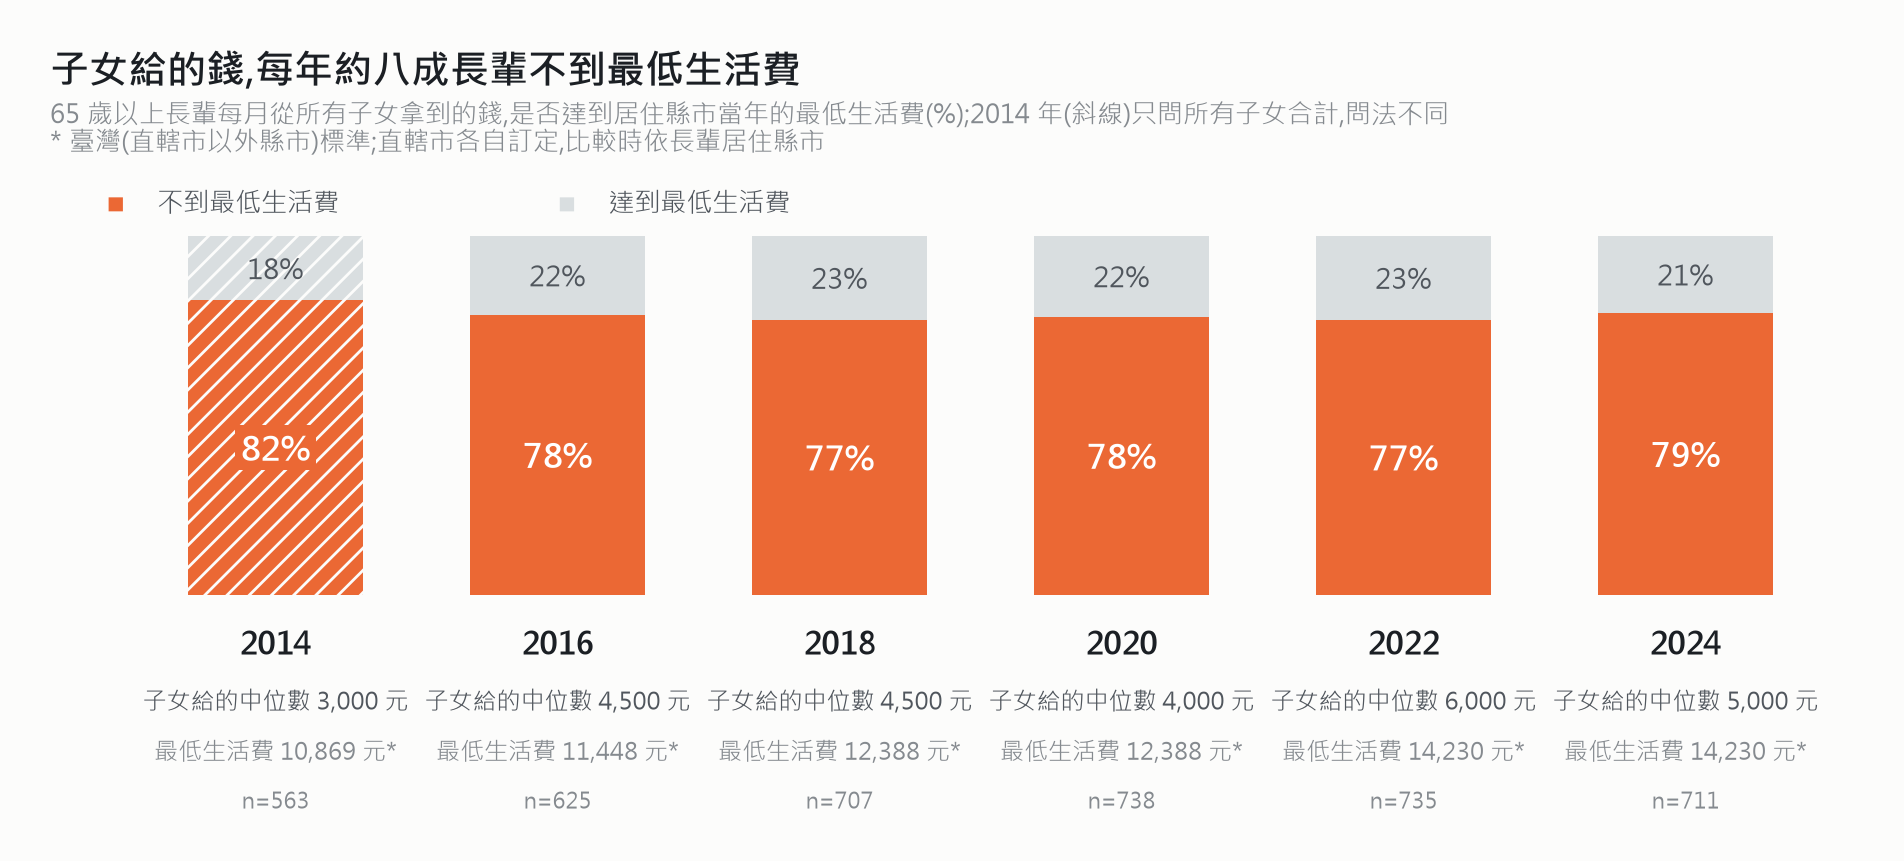

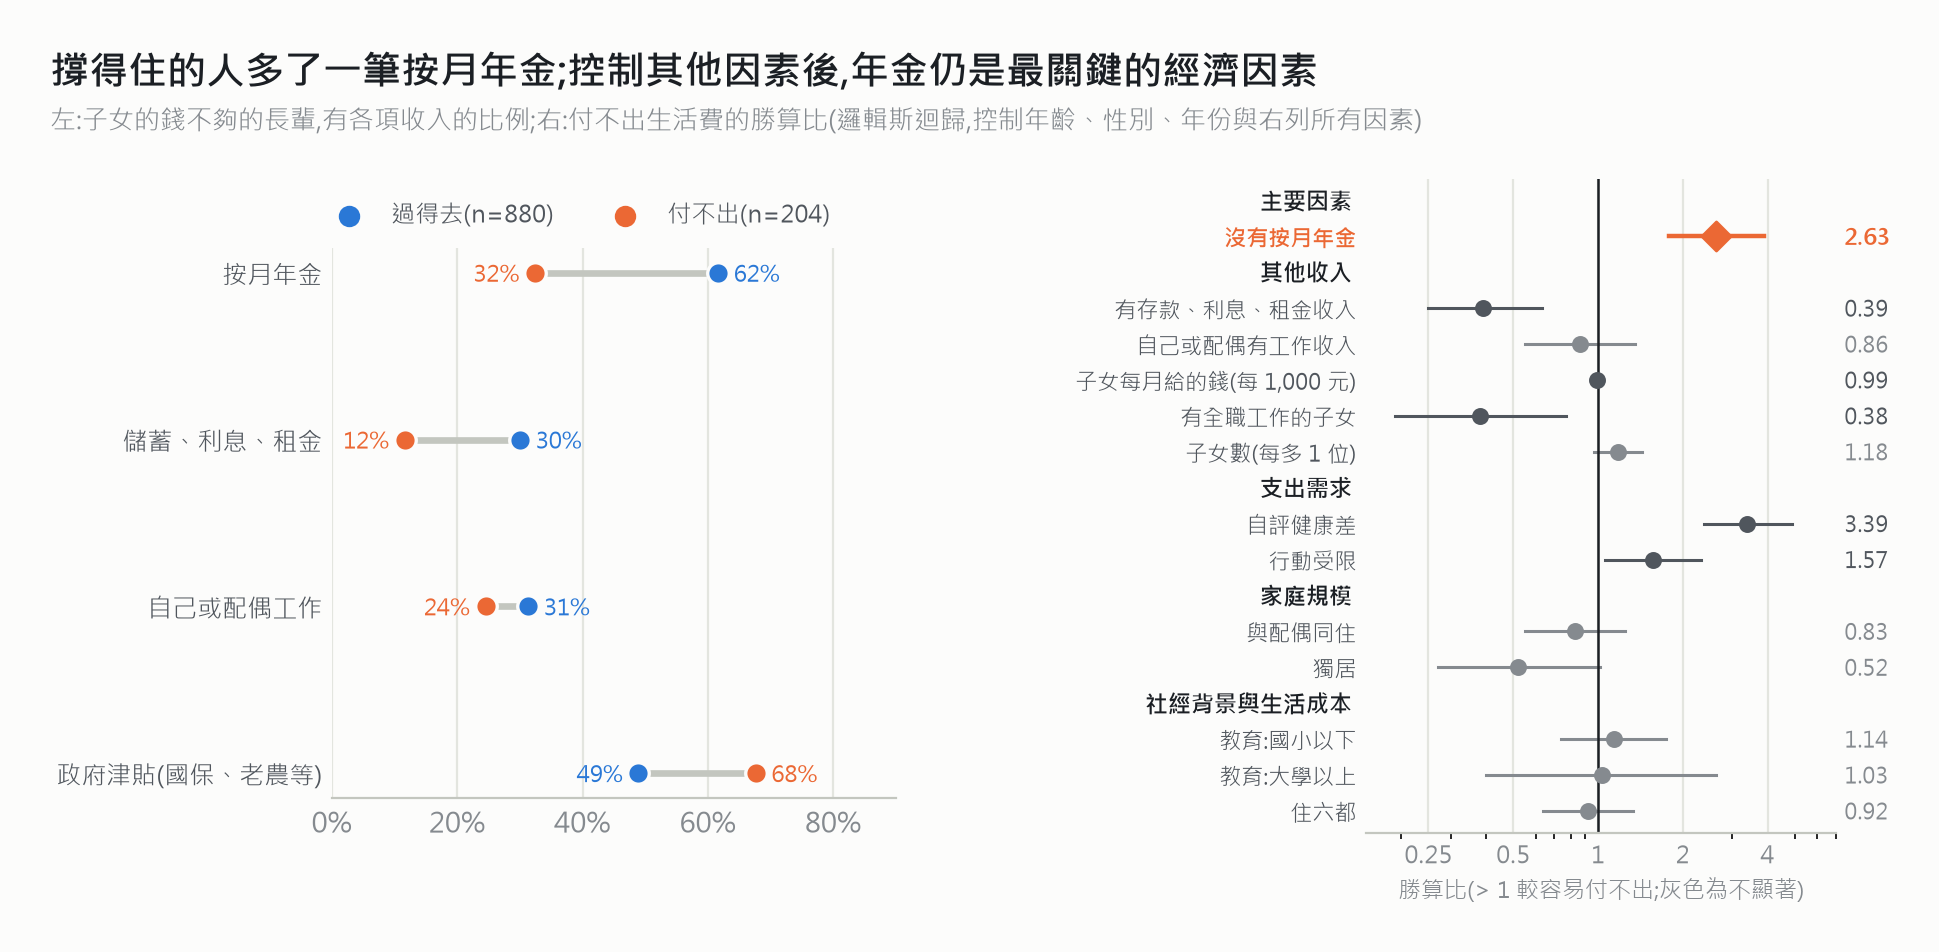

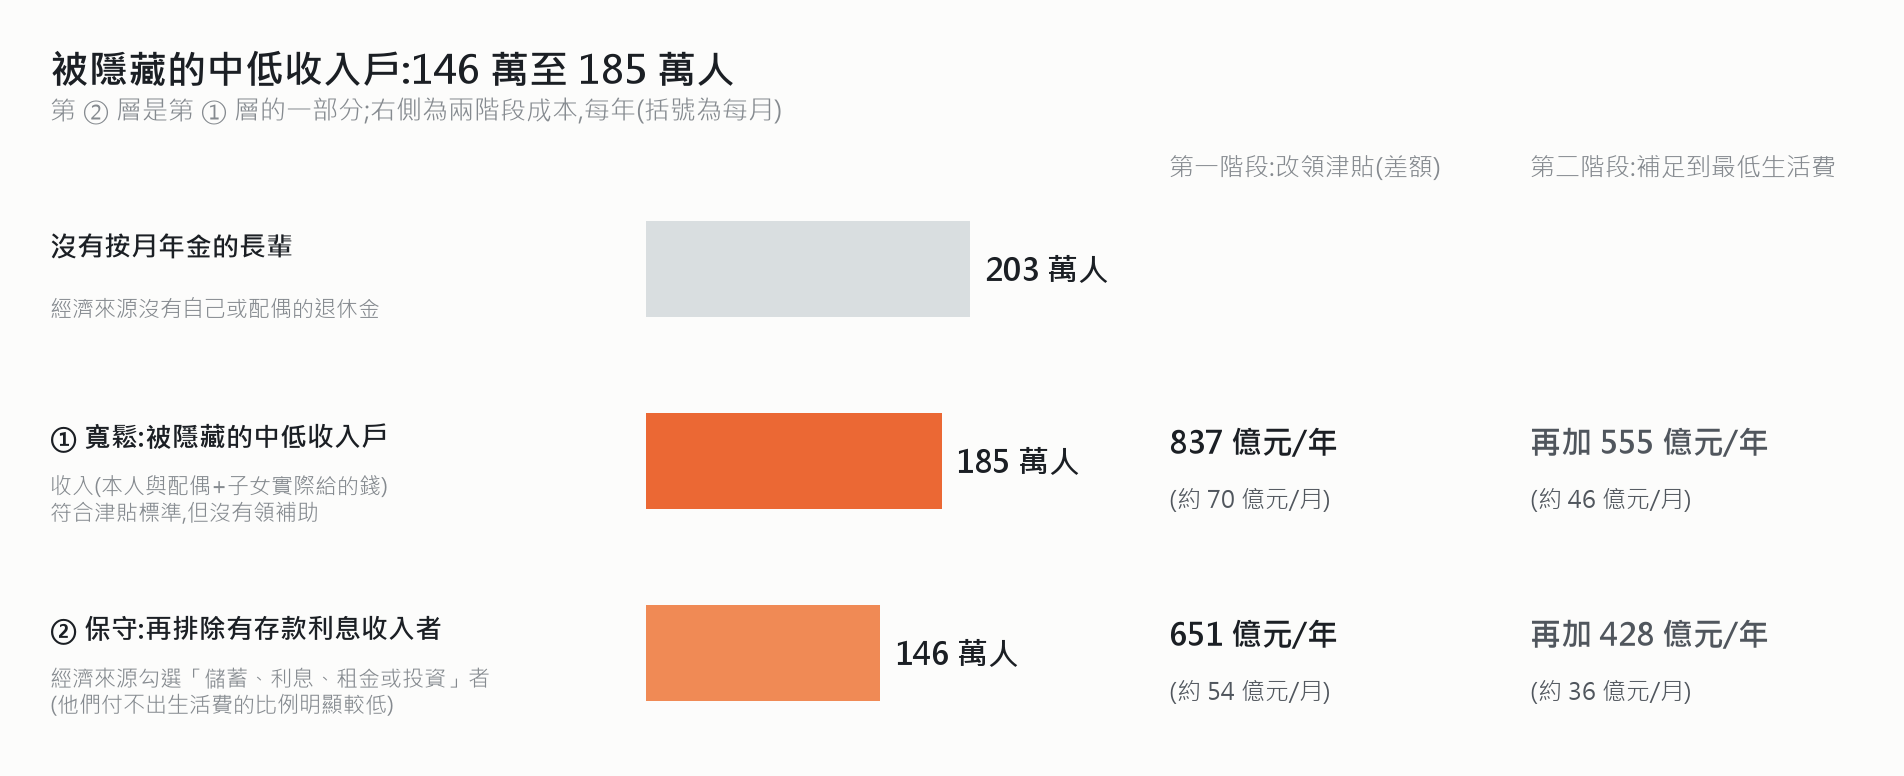

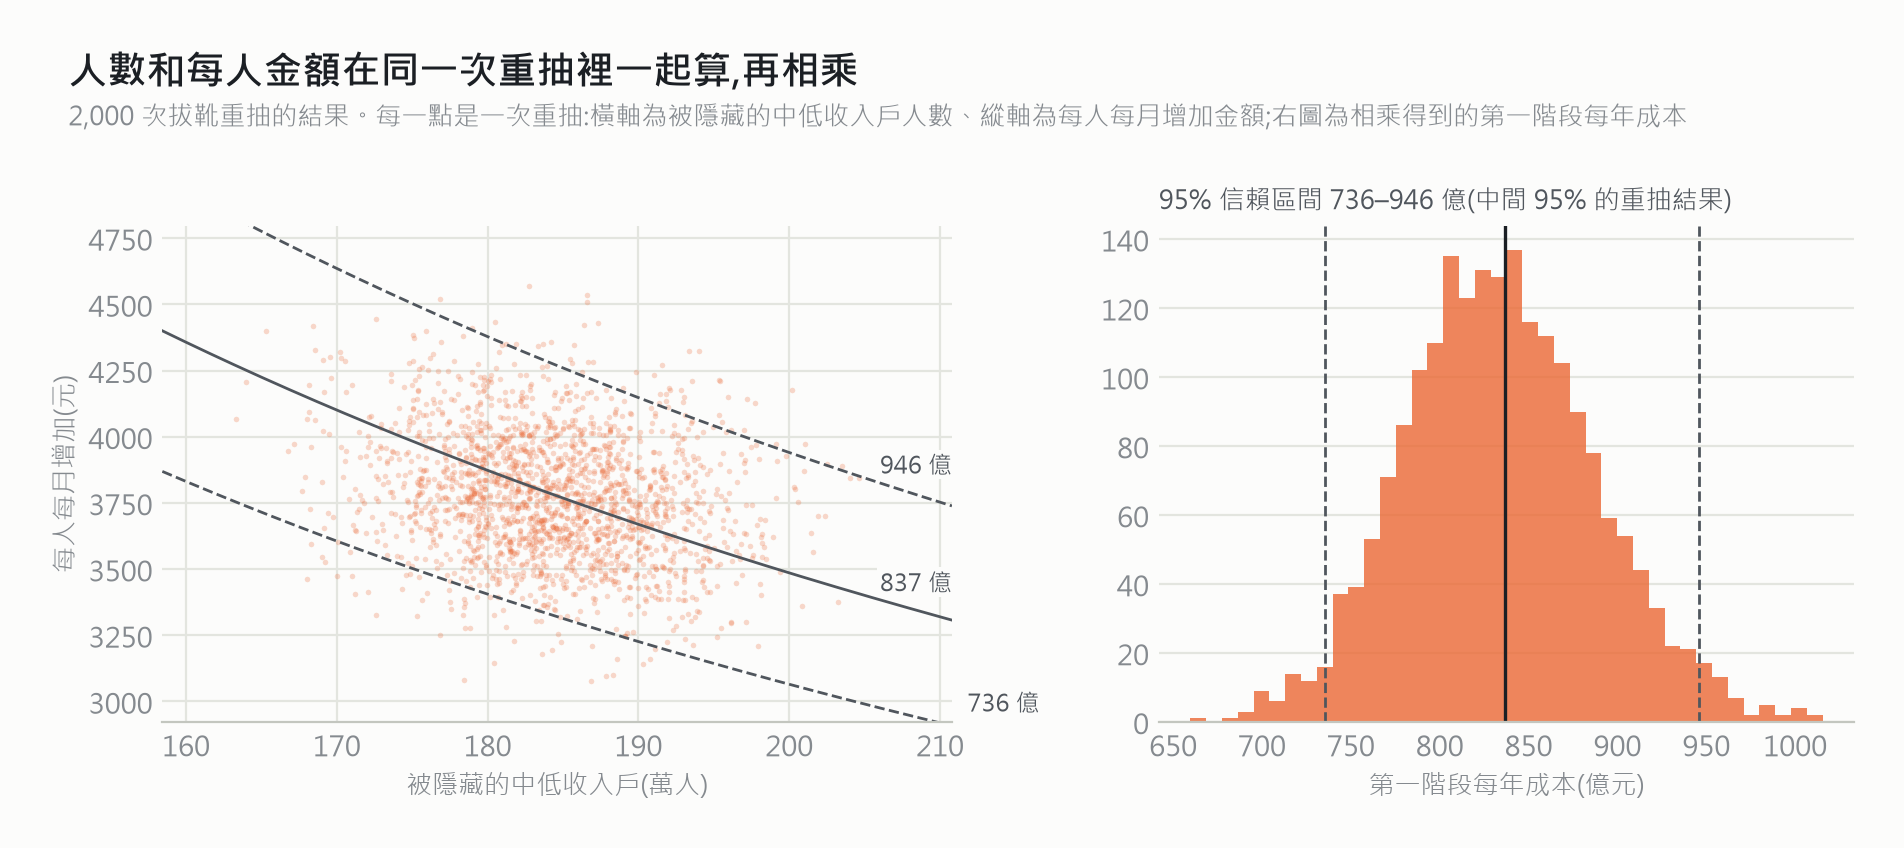

In [12]:
if HAS_DATA:
    from IPython.display import Image
    from pension import figures as F
    E.income_profile(D, J, q_)
    for p in [F.fig_child_trend(J), F.fig_missing_piece(J), F.fig_hidden_funnel(J), F.fig_bootstrap(Bh, est_h)]:
        display(Image(filename=str(p), width=720))